In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, roc_curve, auc)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [3]:
DATA_PATH = "kerala.csv"      # e.g. "FLOOD/kerala.csv" if you kept the folder
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()

Shape: (118, 16)


,SUBDIVISION,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,ANNUAL RAINFALL,FLOODS
0,KERALA,1901,28.7,44.7,51.6,160.0,174.7,824.6,743.0,357.5,197.7,266.9,350.8,48.4,3248.6,YES
1,KERALA,1902,6.7,2.6,57.3,83.9,134.5,390.9,1205.0,315.8,491.6,358.4,158.3,121.5,3326.6,YES
2,KERALA,1903,3.2,18.6,3.1,83.6,249.7,558.6,1022.5,420.2,341.8,354.1,157.0,59.0,3271.2,YES
3,KERALA,1904,23.7,3.0,32.2,71.5,235.7,1098.2,725.5,351.8,222.7,328.1,33.9,3.3,3129.7,YES
4,KERALA,1905,1.2,22.3,9.4,105.9,263.3,850.2,520.5,293.6,217.2,383.5,74.4,0.2,2741.6,NO


In [4]:
# Column names have stray spaces (e.g. ' ANNUAL RAINFALL') and SUBDIVISION has 'KERALA ' vs 'KERALA'
df.columns = df.columns.str.strip().str.replace(" ", "_")
df["SUBDIVISION"] = df["SUBDIVISION"].str.strip()
df["FLOODS"] = df["FLOODS"].str.strip().str.upper()

print("Missing values:\n", df.isna().sum()[df.isna().sum() > 0])
print("Duplicate rows:", df.duplicated().sum())
print("\nClass balance:\n", df["FLOODS"].value_counts())

# Binary target
df["FLOOD"] = (df["FLOODS"] == "YES").astype(int)

months = ["JAN","FEB","MAR","APR","MAY","JUN","JUL","AUG","SEP","OCT","NOV","DEC"]
df.describe().T

Missing values:
 Series([], dtype: int64)
Duplicate rows: 0

Class balance:
 FLOODS
YES    60
NO     58
Name: count, dtype: int64


,count,mean,std,min,25%,50%,75%,max
YEAR,118.0,1959.500000,34.207699,1901.0,1930.250,1959.50,1988.750,2018.0
JAN,118.0,12.218644,15.473766,0.0,2.175,5.80,18.175,83.5
FEB,118.0,15.633898,16.406290,0.0,4.700,8.35,21.400,79.0
MAR,118.0,36.670339,30.063862,0.1,18.100,28.40,49.825,217.2
APR,118.0,110.330508,44.633452,13.1,74.350,110.40,136.450,238.0
MAY,118.0,228.644915,147.548778,53.4,125.050,184.60,264.875,738.8
JUN,118.0,651.617797,186.181363,196.8,535.550,625.60,786.975,1098.2
JUL,118.0,698.220339,228.988966,167.5,533.200,691.65,832.425,1526.5
AUG,118.0,430.369492,181.980463,178.6,316.725,386.25,500.100,1398.9
SEP,118.0,246.207627,121.901131,41.3,155.425,223.55,334.500,526.7


In [5]:
df["MONSOON_TOTAL"]   = df[["JUN","JUL","AUG","SEP"]].sum(axis=1)   # SW monsoon
df["PRE_MONSOON"]     = df[["MAR","APR","MAY"]].sum(axis=1)
df["POST_MONSOON"]    = df[["OCT","NOV","DEC"]].sum(axis=1)
df["JUL_AUG"]         = df[["JUL","AUG"]].sum(axis=1)                # peak flood months
df["MONSOON_SHARE"]   = df["MONSOON_TOTAL"] / df["ANNUAL_RAINFALL"]
df["PEAK_MONTH_RAIN"] = df[months].max(axis=1)
df["RAIN_VARIABILITY"]= df[months].std(axis=1)

df[["YEAR","MONSOON_TOTAL","PRE_MONSOON","POST_MONSOON","JUL_AUG",
    "MONSOON_SHARE","PEAK_MONTH_RAIN","RAIN_VARIABILITY","FLOOD"]].head()

,YEAR,MONSOON_TOTAL,PRE_MONSOON,POST_MONSOON,JUL_AUG,MONSOON_SHARE,PEAK_MONTH_RAIN,RAIN_VARIABILITY,FLOOD
0,1901,2122.8,386.3,666.1,1100.5,0.653451,824.6,265.894507,1
1,1902,2403.3,275.7,638.2,1520.8,0.722449,1205.0,333.143511,1
2,1903,2343.1,336.4,570.1,1442.7,0.716281,1022.5,298.833945,1
3,1904,2398.2,339.4,365.3,1077.3,0.766272,1098.2,338.531094,1
4,1905,1881.5,378.6,458.1,814.1,0.686278,850.2,258.397795,0


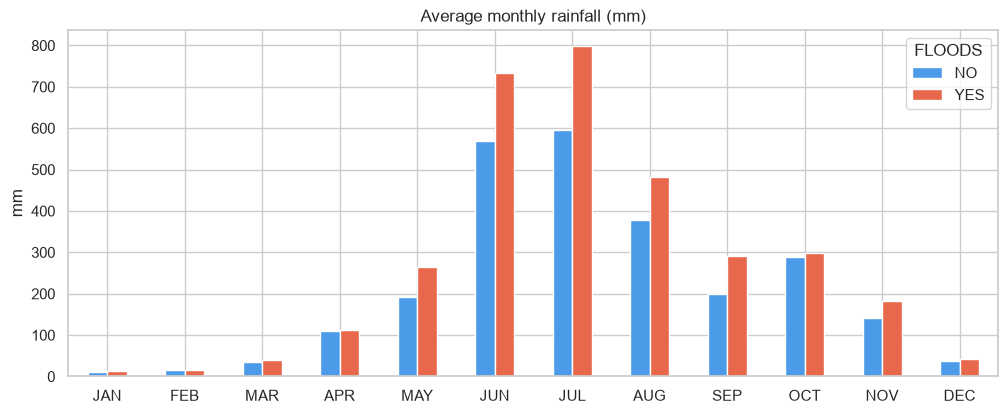

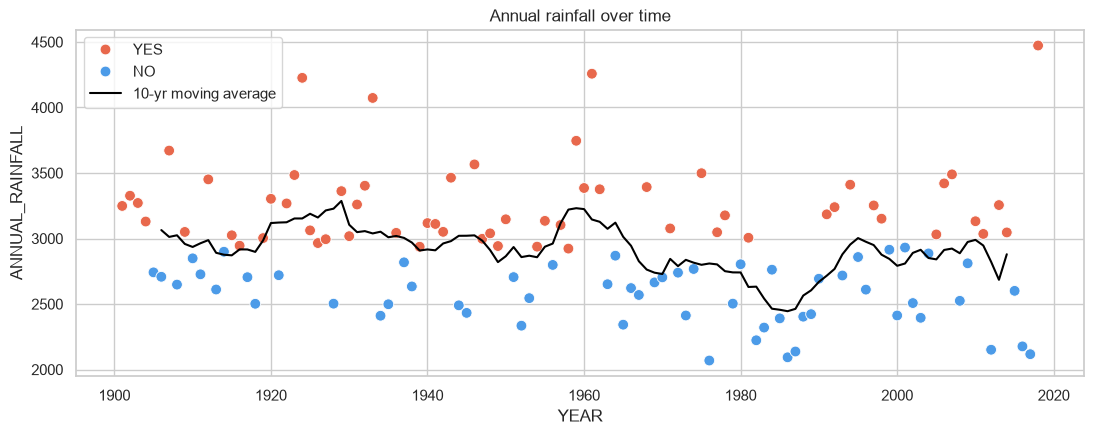

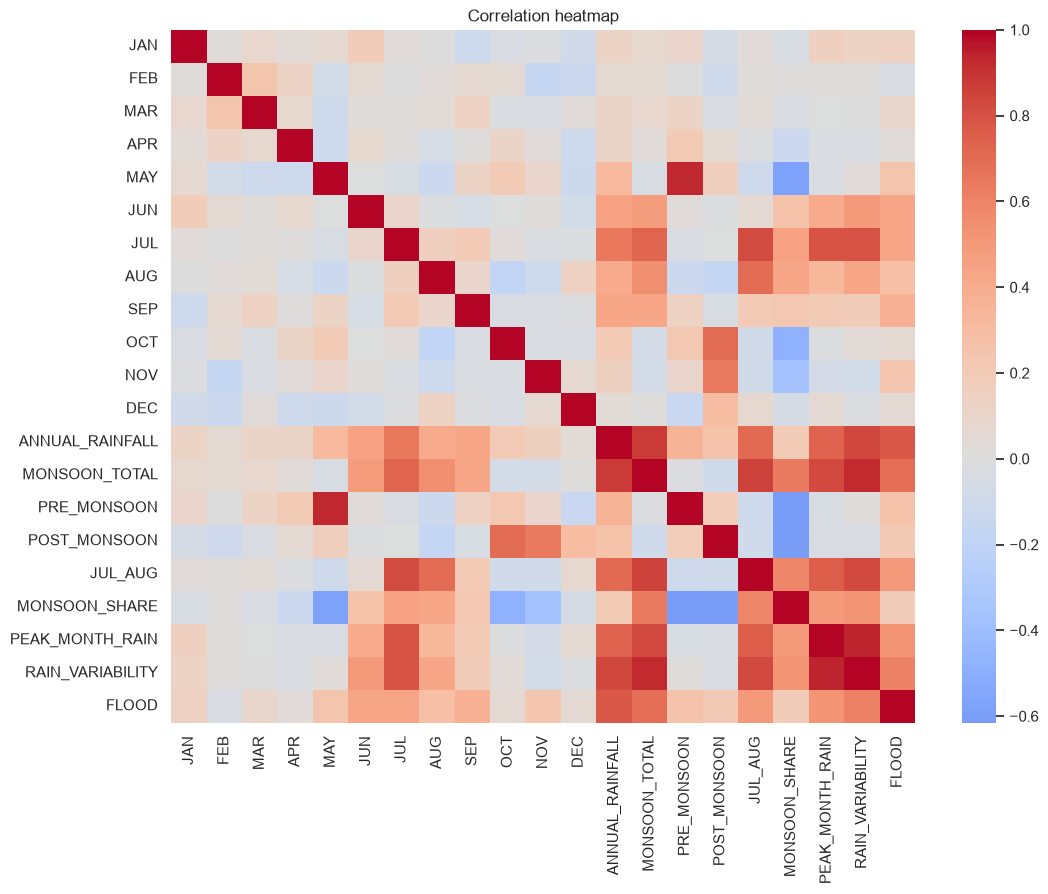

Correlation with FLOOD:


ANNUAL_RAINFALL     0.776231
MONSOON_TOTAL       0.686138
RAIN_VARIABILITY    0.610941
PEAK_MONTH_RAIN     0.524064
JUL_AUG             0.489473
JUL                 0.442774
JUN                 0.442531
SEP                 0.376385
AUG                 0.286690
PRE_MONSOON         0.266803
MAY                 0.242813
NOV                 0.238852
POST_MONSOON        0.211906
MONSOON_SHARE       0.187365
JAN                 0.145313
MAR                 0.086739
OCT                 0.060088
DEC                 0.054326
APR                 0.034392
FEB                -0.035730
Name: FLOOD, dtype: float64

In [18]:

monthly = df.groupby("FLOODS")[months].mean().T
monthly.plot(kind="bar", figsize=(12, 4.5), color=["#4C9BE8", "#E8684C"])
plt.title("Average monthly rainfall (mm)"); plt.ylabel("mm"); plt.xticks(rotation=0)
plt.show()
# Rainfall trend over the years, coloured by flood outcome
plt.figure(figsize=(13, 4.5))
sns.scatterplot(data=df, x="YEAR", y="ANNUAL_RAINFALL", hue="FLOODS",
                palette={"NO": "#4C9BE8", "YES": "#E8684C"}, s=60)
plt.plot(df["YEAR"], df["ANNUAL_RAINFALL"].rolling(10, center=True).mean(),
         color="black", lw=1.5, label="10-yr moving average")
plt.title("Annual rainfall over time"); plt.legend(); plt.show()
# Correlation of features with the flood label
feat_cols = months + ["ANNUAL_RAINFALL","MONSOON_TOTAL","PRE_MONSOON","POST_MONSOON",
                      "JUL_AUG","MONSOON_SHARE","PEAK_MONTH_RAIN","RAIN_VARIABILITY"]
corr = df[feat_cols + ["FLOOD"]].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False)
plt.title("Correlation heatmap"); plt.show()

print("Correlation with FLOOD:")
corr["FLOOD"].drop("FLOOD").sort_values(ascending=False)


In [7]:
# 'YEAR' is excluded: we want the model to learn from rainfall, not from the calendar.
features = feat_cols
X = df[features]
y = df["FLOOD"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (88, 20)  Test: (30, 20)


In [8]:
models = {
    "Logistic Regression": Pipeline([("scaler", StandardScaler()),
                                     ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]),
    "Random Forest":       RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
    "SVM (RBF)":           Pipeline([("scaler", StandardScaler()),
                                     ("clf", SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE))]),
    "KNN":                 Pipeline([("scaler", StandardScaler()),
                                     ("clf", KNeighborsClassifier(n_neighbors=5))]),
}

results, preds, probas = [], {}, {}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    preds[name], probas[name] = y_pred, model.predict_proba(X_test)[:, 1]
    results.append({
        "Model": name,
        "Accuracy":  accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall":    recall_score(y_test, y_pred),
        "F1-score":  f1_score(y_test, y_pred),
    })

results_df = pd.DataFrame(results).set_index("Model").round(3)
results_df.sort_values("F1-score", ascending=False)

,Accuracy,Precision,Recall,F1-score
Model,,,,
Random Forest,1.000,1.000,1.000,1.000
Logistic Regression,0.967,0.938,1.000,0.968
KNN,0.967,1.000,0.933,0.966
SVM (RBF),0.933,0.882,1.000,0.938


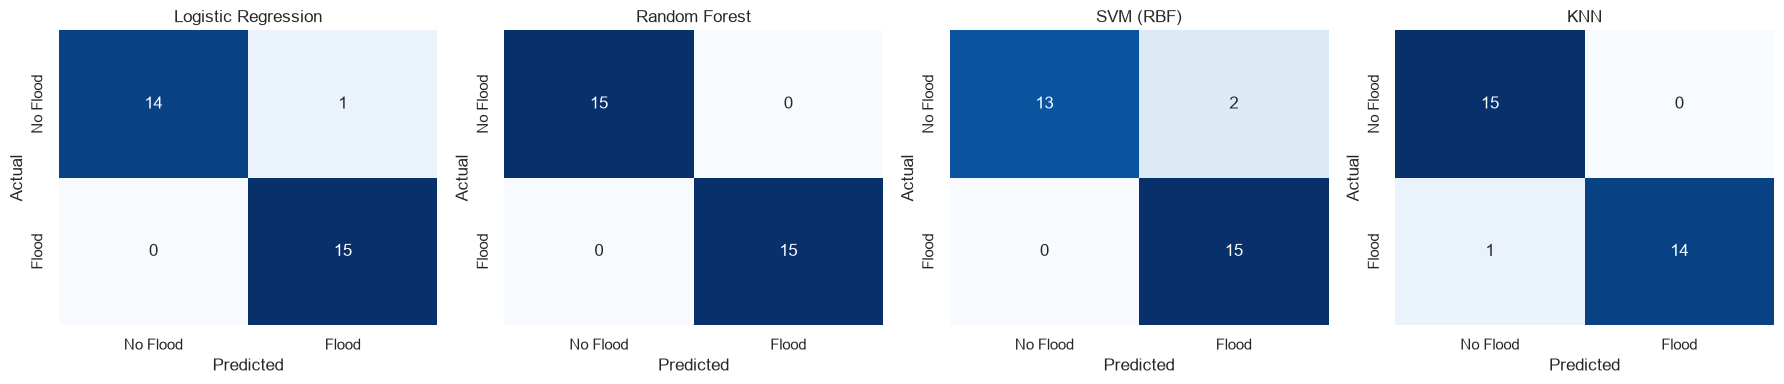

<Figure size 700x600 with 0 Axes>

<Figure size 700x600 with 0 Axes>

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (name, y_pred) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["No Flood", "Flood"], yticklabels=["No Flood", "Flood"])
    ax.set_title(name); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()
plt.figure(figsize=(7, 6))


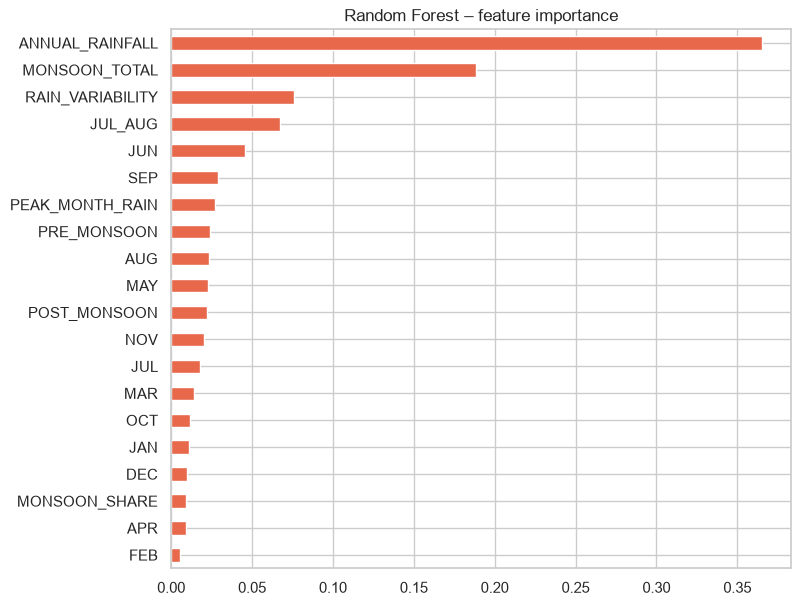

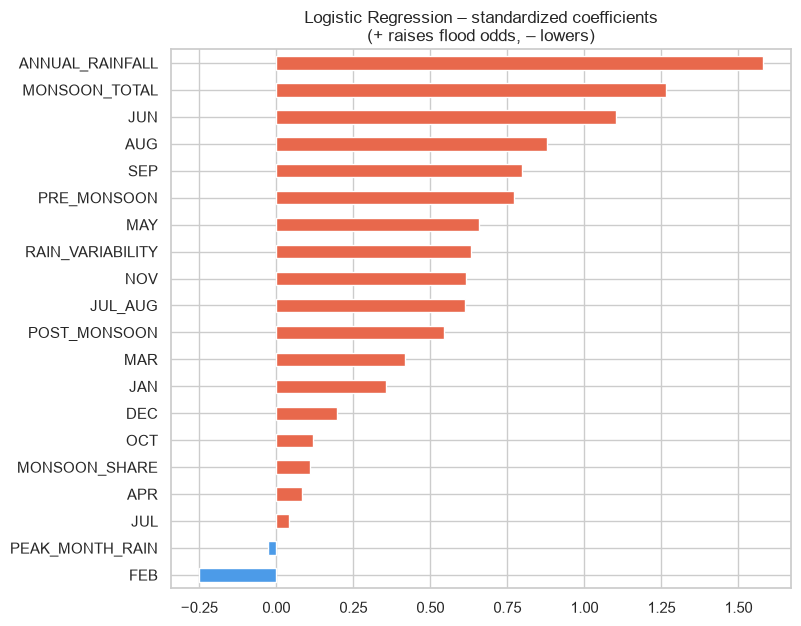

In [11]:
rf = models["Random Forest"]
imp = pd.Series(rf.feature_importances_, index=features).sort_values()
imp.plot(kind="barh", figsize=(8, 7), color="#E8684C")
plt.title("Random Forest – feature importance"); plt.show()
lr = models["Logistic Regression"].named_steps["clf"]
coefs = pd.Series(lr.coef_[0], index=features).sort_values()
coefs.plot(kind="barh", figsize=(8, 7), color=np.where(coefs > 0, "#E8684C", "#4C9BE8"))
plt.title("Logistic Regression – standardized coefficients\n(+ raises flood odds, – lowers)")
plt.show()
